# PSF Comparison (FLIP forward pass VS STPSF)

## FLIP forward PSF

In [2]:
from pathlib import Path
import sys
import torch

FLIP_DIR = Path("/Users/yuxinzhang/Desktop/Caltech_Research/pyflip")

if str(FLIP_DIR) not in sys.path:
    sys.path.insert(0, str(FLIP_DIR))

from dl_utils import load_data
from propagation_classes import BroadbandWavefront, PointPropagate
from model_classes import OPDOffsetModule

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("FLIP imports successful.")
print("Device:", device)

FLIP imports successful.
Device: cpu


### Load the data(Aperture + Lyot + Focal-plane mask + Instrument OPD + Input wave)

In [3]:
DATA_DIR = FLIP_DIR / "HIP65426" / "model_setup"

aperture_np, lyot_np, fpm_np, nircam_opd_np, spectral_table = load_data(
    data_dir=str(DATA_DIR),
    num_wl=21,
    oversample=2
)

print("Aperture shape:", aperture_np.shape)
print("Lyot stop shape:", lyot_np.shape)
print("Focal-plane masks shape:", fpm_np.shape)
print("NIRCam OPD shape:", nircam_opd_np.shape)
print("Wavelength table shape:", spectral_table.shape)

Aperture shape: (1024, 1024)
Lyot stop shape: (1024, 1024)
Focal-plane masks shape: (21, 2048, 2048)
NIRCam OPD shape: (21, 1024, 1024)
Wavelength table shape: (2, 21)


### Load telescope OPD

In [4]:
import numpy as np

opd_path = DATA_DIR / "opds_dates" / "observation_opd.npy"

telescope_opd_raw = np.load(opd_path)

# Match the orientation used by FLIP's original script.
telescope_opd_np = np.flip(telescope_opd_raw, axis=0).copy()

print("Telescope OPD shape:", telescope_opd_np.shape)

Telescope OPD shape: (1024, 1024)


In [5]:
# convert all to sensors
aperture = torch.tensor(
    aperture_np.copy(), dtype=torch.float32, device=device
)[None]

lyot = torch.tensor(
    lyot_np.copy(), dtype=torch.float32, device=device
)[None]

fpm = torch.tensor(
    fpm_np.copy(), dtype=torch.float32, device=device
)[None]

nircam_opd = torch.tensor(
    nircam_opd_np.copy(), dtype=torch.float64, device=device
)[None]

telescope_opd = torch.tensor(
    telescope_opd_np, dtype=torch.float32, device=device
)

spectral = torch.tensor(
    spectral_table, dtype=torch.float32, device=device
)

wavelengths = spectral[0]
weights = spectral[1]

## Default setting value

In [6]:
pupil_pixels = 1024
pupil_diameter_m = 6.603464

num_detector_pixels = 80
pixel_scale_arcsec = 0.062424185

oversample = 2

In [7]:
contrast_normalization = 0.003716380479003919
sim_to_real_scaling = 2.1722325193439986

photons_normalization = (
    90578.00102527262
    * sim_to_real_scaling
    * 1e4
    / 2251.24456327477
)

peak_flux = torch.tensor(
    [photons_normalization / contrast_normalization],
    dtype=torch.float32,
    device=device
)

print("Initial source flux parameter:", peak_flux.item())

Initial source flux parameter: 235172320.0


## Inject the Star position

In [8]:
# Center the star on the optical axis.
source_angles = torch.zeros(
    2,
    dtype=torch.float32,
    device=device
)

print("Source angles (radians):", source_angles)

Source angles (radians): tensor([0., 0.])


### Combine all the infor for input star

In [9]:
wavefront = BroadbandWavefront(
    npixels=pupil_pixels,
    diameter=pupil_diameter_m,
    wavelength=wavelengths.detach().cpu().numpy(),
    peak_flux=peak_flux,
    angles=source_angles,
    DEVICE=str(device)
).to(device)

### Prepare the arg for propagation

In [10]:
from dl_utils import arcsec2rad

propagation_args = (
    pupil_pixels,
    wavelengths,
    pupil_diameter_m / pupil_pixels,
    num_detector_pixels,
    arcsec2rad(pixel_scale_arcsec),
    None,
    [0.0, 0.0],
    True,
    False
)

In [11]:
# Initialize a zero-valued telescope OPD correction map.
telescope_correction = OPDOffsetModule(
    pupil_pixels,
    pupil_pixels
)

print("OPD correction module created.")

OPD correction module created.


### Combine all the information for the model

In [12]:
model = PointPropagate(
    aperture=aperture,
    lyot=lyot,
    fpm=fpm,
    nircam_opd=nircam_opd,
    args=propagation_args,
    oversample=oversample,
    OTE_wfe_basis=telescope_correction,
    num_det_px=num_detector_pixels
).to(device)

print("FLIP optical model created.")

FLIP optical model created.


### Forward pass

In [13]:
# Generate one PSF without tracking gradients.
with torch.no_grad():
    prediction = model(
        wavefront,
        telescope_opd,
        weights,
        wavelengths
    )

print("Output shape:", prediction.shape)

Output shape: torch.Size([1, 80, 80])


/Users/yuxinzhang/Desktop/Caltech_Research/pyflip/model_classes.py:341: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1136.)
  blurred = F.conv2d(x_reshaped, kernel_2d, padding='same')


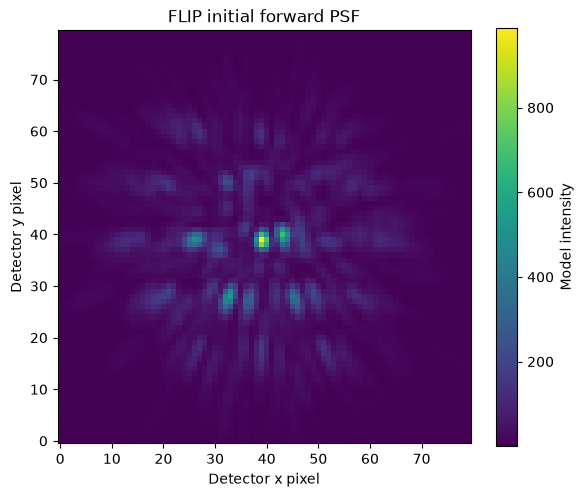

In [14]:
import matplotlib.pyplot as plt

# Remove the leading size-one dimension and convert to NumPy.
flip_psf = prediction.squeeze(0).detach().cpu().numpy()

plt.figure(figsize=(6, 5))
plt.imshow(flip_psf, origin="lower", cmap="viridis")
plt.title("FLIP initial forward PSF")
plt.xlabel("Detector x pixel")
plt.ylabel("Detector y pixel")
plt.colorbar(label="Model intensity")
plt.tight_layout()
plt.show()

## PSF with STPSF

## Prepare for the NIRCam instance

In [15]:
import stpsf

inst_matched = stpsf.NIRCam()
inst_matched.filter = "F444W"
inst_matched.image_mask = "MASK335R"
inst_matched.pupil_mask = "CIRCLYOT"

print("STPSF instrument configured.")

STPSF instrument configured.


## copy the input data

In [16]:
matched_source = {
    "wavelengths": wavelengths.detach().cpu().numpy().copy(),
    "weights": weights.detach().cpu().numpy().copy()
}

print("Number of wavelengths:", len(matched_source["wavelengths"]))
print("Weight sum:", matched_source["weights"].sum())

Number of wavelengths: 21
Weight sum: 1.0


### Load the telescope OPD

In [17]:
from astropy.io import fits
opd_array = telescope_opd.detach().cpu().numpy()

## flip back the opd
stpsf_input_opd = np.flipud(opd_array).copy()
## store in the FITS for stpsf to load
opd_hdu = fits.PrimaryHDU(data=stpsf_input_opd)
opd_hdu.header["BUNIT"] = "meter"
## length for each pixel
opd_hdu.header["PUPLSCAL"] = pupil_diameter_m / pupil_pixels

inst_matched.pupilopd = fits.HDUList([opd_hdu])
# Disable the additional nominal telescope field-dependent correction.
inst_matched.include_ote_field_dependence = False





## test whether equal

# Retrieve the effective telescope OPD in meters.
effective_stpsf_opd = inst_matched.get_wfe("ote")

# Restore the aperture to the same orientation as the STPSF input.
inside_pupil = np.flipud(aperture_np) > 0

# Compare the supplied and effective telescope OPDs.
difference_nm = (
    effective_stpsf_opd[inside_pupil]
    - stpsf_input_opd[inside_pupil]
) * 1e9

print(
    "Maximum absolute OPD difference (nm):",
    np.max(np.abs(difference_nm))
)

Maximum absolute OPD difference (nm): 0.0


In [18]:
# Inspect the optical planes without calculating a PSF.
optical_system = inst_matched.get_optical_system()

for index, plane in enumerate(optical_system.planes):
    print(index, plane.name, getattr(plane, "axis", ""))

0 JWST Entrance Pupil 
1 OTE exit pupil y
2 MASK335R 
3 CIRCLYOT 
4 NIRCamLWA internal WFE at V2V3=(1.79,-6.75)', near Z335R_A 
5 NIRCam detector 


In [19]:
# Match FLIP's detector pixel scale.
inst_matched.pixelscale = pixel_scale_arcsec

print("STPSF pixel scale (arcsec/pixel):", inst_matched.pixelscale)

STPSF pixel scale (arcsec/pixel): 0.062424185


### Inject star position

In [20]:
# Center the source on the optical axis.
inst_matched.options["source_offset_r"] = 0.0
inst_matched.options["source_offset_theta"] = 0.0

In [21]:
# Disable additional pointing-jitter blur.
inst_matched.options["jitter"] = None

### Generate PSF with STPSF

In [22]:
psf_stpsf = inst_matched.calc_psf(
    source=matched_source,
    fov_pixels=num_detector_pixels,
    oversample=oversample,
    add_distortion=False
)

stpsf_detector_psf = psf_stpsf["DET_SAMP"].data.copy()

print("Updated STPSF PSF shape:", stpsf_detector_psf.shape)

Updated STPSF PSF shape: (80, 80)


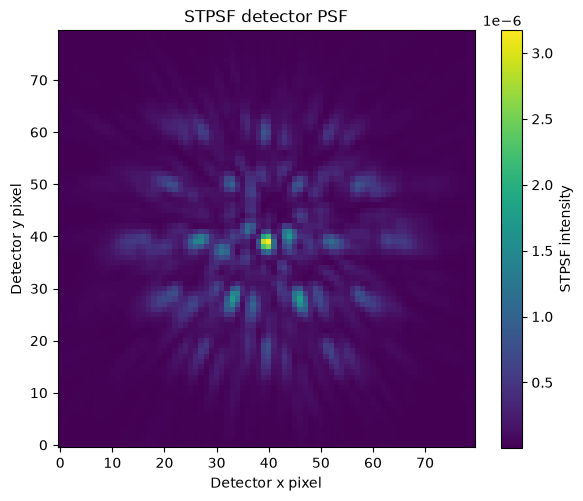

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.imshow(
    stpsf_detector_psf,
    origin="lower",
    cmap="viridis"
)
plt.title("STPSF detector PSF")
plt.xlabel("Detector x pixel")
plt.ylabel("Detector y pixel")
plt.colorbar(label="STPSF intensity")
plt.tight_layout()
plt.show()

## Residual calculation and analysis (FLIP VS stpsf)

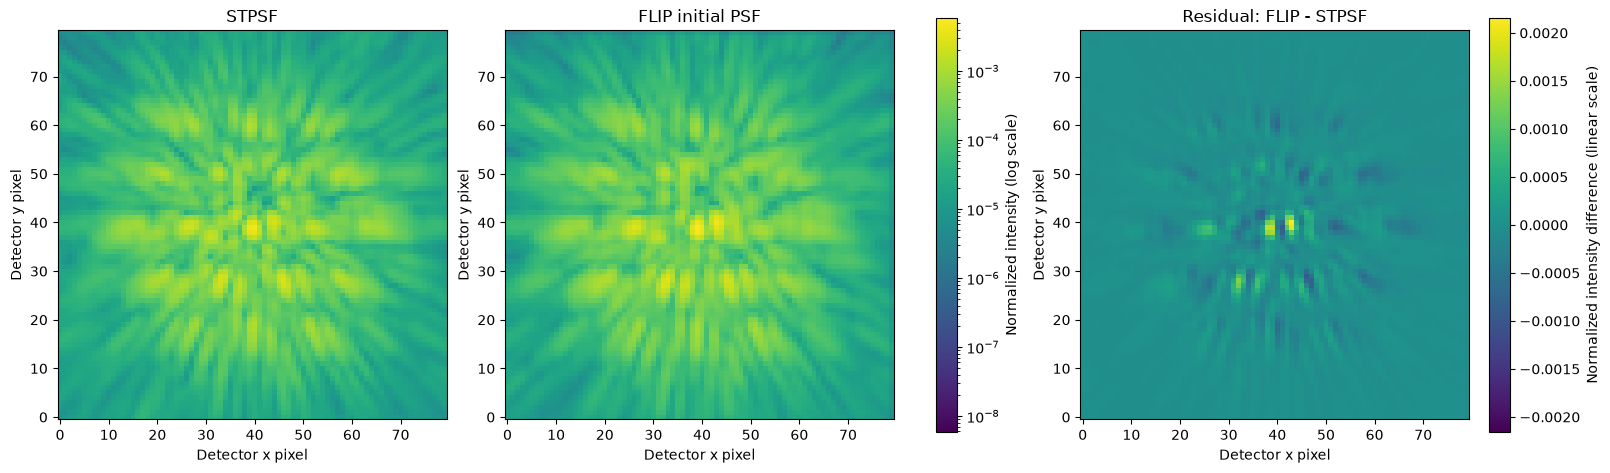

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize

stpsf_image = np.asarray(stpsf_detector_psf, dtype=float)
flip_image = np.asarray(flip_psf, dtype=float)

if stpsf_image.shape != flip_image.shape:
    raise ValueError("PSF shapes must match.")

for image in [stpsf_image, flip_image]:
    if not np.isfinite(image).all() or image.sum() <= 0:
        raise ValueError("PSFs must be finite with positive total intensity.")

# Normalize each PSF to unit total intensity.
stpsf_norm = stpsf_image / stpsf_image.sum()
flip_norm = flip_image / flip_image.sum()
residual = flip_norm - stpsf_norm

# Shared logarithmic scale for the two PSFs.
peak = max(stpsf_norm.max(), flip_norm.max())
psf_scale = LogNorm(vmin=peak * 1e-6, vmax=peak)

# Separate symmetric linear scale for the signed residual.
limit = max(np.max(np.abs(residual)), np.finfo(float).eps)
residual_scale = Normalize(vmin=-limit, vmax=limit)

fig, axes = plt.subplots(
    1, 3, figsize=(16, 5), constrained_layout=True
)

for ax, image, title in zip(
    axes[:2],
    [stpsf_norm, flip_norm],
    ["STPSF", "FLIP initial PSF"]
):
    im = ax.imshow(
        np.ma.masked_less_equal(image, 0),
        origin="lower",
        cmap="viridis",
        norm=psf_scale
    )
    ax.set_title(title)

fig.colorbar(
    im, ax=axes[:2],
    label="Normalized intensity (log scale)",
    shrink=0.85
)

res = axes[2].imshow(
    residual,
    origin="lower",
    cmap="viridis",
    norm=residual_scale
)
axes[2].set_title("Residual: FLIP - STPSF")

fig.colorbar(
    res, ax=axes[2],
    label="Normalized intensity difference (linear scale)",
    shrink=0.85
)

for ax in axes:
    ax.set_xlabel("Detector x pixel")
    ax.set_ylabel("Detector y pixel")

plt.show()

## Visualization for each component

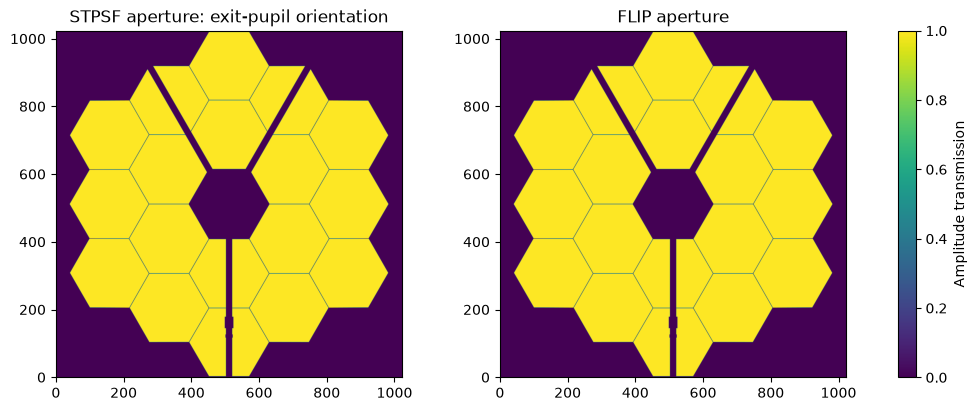

Maximum aperture difference: 0.0


In [25]:
# Get STPSF's entrance-pupil transmission.
optical_system = inst_matched.get_optical_system()
test_wave = optical_system.input_wavefront(
    wavelength=float(wavelengths[0].item())
)

stpsf_aperture = optical_system.planes[0].get_transmission(test_wave)

# Compare both apertures in FLIP's exit-pupil orientation.
stpsf_aperture_aligned = np.flipud(stpsf_aperture)
flip_aperture_used = aperture[0].detach().cpu().numpy()

fig, axes = plt.subplots(
    1, 2, figsize=(10, 4), constrained_layout=True
)

for ax, image, title in zip(
    axes,
    [stpsf_aperture_aligned, flip_aperture_used],
    ["STPSF aperture: exit-pupil orientation", "FLIP aperture"]
):
    im = ax.imshow(
        image,
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1
    )
    ax.set_title(title)

fig.colorbar(im, ax=axes, label="Amplitude transmission")
plt.show()

print(
    "Maximum aperture difference:",
    np.max(np.abs(stpsf_aperture_aligned - flip_aperture_used))
)

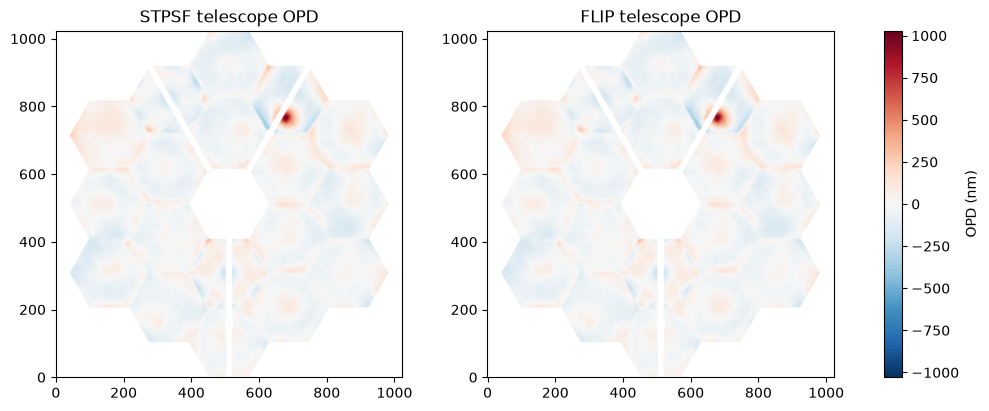

Maximum telescope OPD difference (nm): 4.105415428057313e-05


In [26]:
# Retrieve STPSF's telescope OPD in entrance-pupil orientation.
stpsf_ote = inst_matched.get_wfe("ote")

# Convert to the orientation used by FLIP.
stpsf_ote_aligned = np.flipud(stpsf_ote)
flip_ote = telescope_opd.detach().cpu().numpy()

# Display only positions where both apertures transmit light.
inside = (
    (stpsf_aperture_aligned > 0)
    & (flip_aperture_used > 0)
)

stpsf_map = np.where(inside, stpsf_ote_aligned * 1e9, np.nan)
flip_map = np.where(inside, flip_ote * 1e9, np.nan)

limit = max(
    np.nanmax(np.abs(stpsf_map)),
    np.nanmax(np.abs(flip_map))
)

fig, axes = plt.subplots(
    1, 2, figsize=(10, 4), constrained_layout=True
)

for ax, image, title in zip(
    axes,
    [stpsf_map, flip_map],
    ["STPSF telescope OPD", "FLIP telescope OPD"]
):
    im = ax.imshow(
        image,
        origin="lower",
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit
    )
    ax.set_title(title)

fig.colorbar(im, ax=axes, label="OPD (nm)")
plt.show()

print(
    "Maximum telescope OPD difference (nm):",
    np.max(np.abs(stpsf_map[inside] - flip_map[inside]))
)

Wavelength (microns): 4.454522695596097
STPSF mask shape: (2048, 2048)
FLIP mask shape: (2048, 2048)


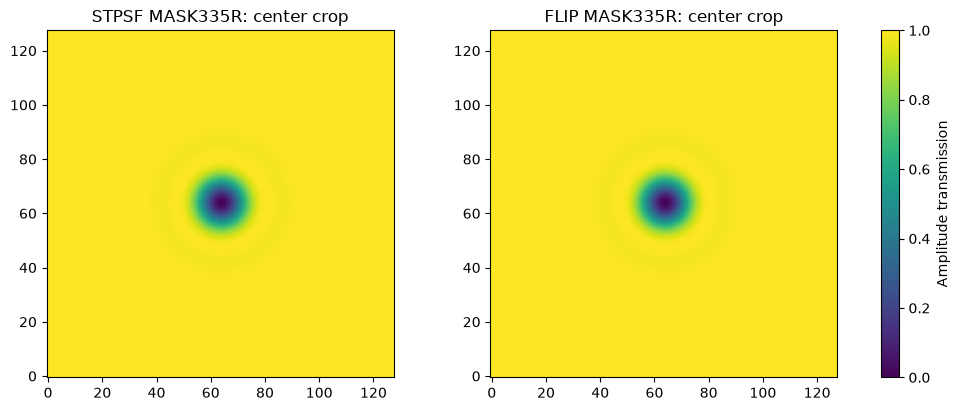

Maximum mask difference: 2.9685294111736482e-08


In [27]:
# Select the middle wavelength.
wl_index = len(wavelengths) // 2
wl_m = float(wavelengths[wl_index].item())

# Propagate to the mask plane to obtain the correct sampling grid.
optical_system = inst_matched.get_optical_system(fft_oversample=oversample)
mask_wave = optical_system.input_wavefront(wavelength=wl_m)

for plane in optical_system.planes:
    mask_wave.propagate_to(plane)

    if plane.name == "MASK335R":
        stpsf_mask = plane.get_transmission(mask_wave)
        break

    mask_wave *= plane
else:
    raise RuntimeError("MASK335R was not found.")

flip_mask = fpm[0, wl_index].detach().cpu().numpy()

print("Wavelength (microns):", wl_m * 1e6)
print("STPSF mask shape:", stpsf_mask.shape)
print("FLIP mask shape:", flip_mask.shape)

assert stpsf_mask.shape == flip_mask.shape

# Display the central 128 x 128 samples.
cy, cx = np.array(stpsf_mask.shape) // 2
crop = np.s_[cy - 64:cy + 64, cx - 64:cx + 64]

fig, axes = plt.subplots(
    1, 2, figsize=(10, 4), constrained_layout=True
)

for ax, image, title in zip(
    axes,
    [stpsf_mask, flip_mask],
    ["STPSF MASK335R: center crop", "FLIP MASK335R: center crop"]
):
    im = ax.imshow(
        np.abs(image[crop]),
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1
    )
    ax.set_title(title)

fig.colorbar(im, ax=axes, label="Amplitude transmission")
plt.show()

# Compare the full arrays, not just the displayed crop.
print(
    "Maximum mask difference:",
    np.max(np.abs(stpsf_mask - flip_mask))
)

In [28]:
# Retrieve STPSF's Lyot transmission at the correct optical plane.
optical_system = inst_matched.get_optical_system(
    fft_oversample=oversample
)
lyot_wave = optical_system.input_wavefront(wavelength=wl_m)

for plane in optical_system.planes:
    lyot_wave.propagate_to(plane)

    if "lyot" in plane.name.lower():
        stpsf_lyot_used = np.asarray(
            plane.get_transmission(lyot_wave)
        ).copy()
        print("STPSF Lyot element:", plane.name)
        break

    lyot_wave *= plane
else:
    raise RuntimeError("Lyot stop was not found.")

# Include FLIP's actual interpolation step.
with torch.no_grad():
    flip_lyot_used = (
        model.lyot_shifts(model.lyot)[0]
        .detach().cpu().numpy().copy()
    )

print("STPSF Lyot shape:", stpsf_lyot_used.shape)
print("FLIP Lyot shape:", flip_lyot_used.shape)

assert stpsf_lyot_used.shape == flip_lyot_used.shape

fig, axes = plt.subplots(
    1, 2, figsize=(10, 4), constrained_layout=True
)

for ax, image, title in zip(
    axes,
    [stpsf_lyot_used, flip_lyot_used],
    ["STPSF current Lyot stop", "FLIP effective Lyot stop"]
):
    im = ax.imshow(
        image,
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1
    )
    ax.set_title(title)

fig.colorbar(im, ax=axes, label="Amplitude transmission")
plt.show()

print(
    "Maximum Lyot difference:",
    np.max(np.abs(stpsf_lyot_used - flip_lyot_used))
    "sum Lyot difference:",
    np.sum(np.abs(stpsf_lyot_used - flip_lyot_used))

)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1201107593.py, line 56)

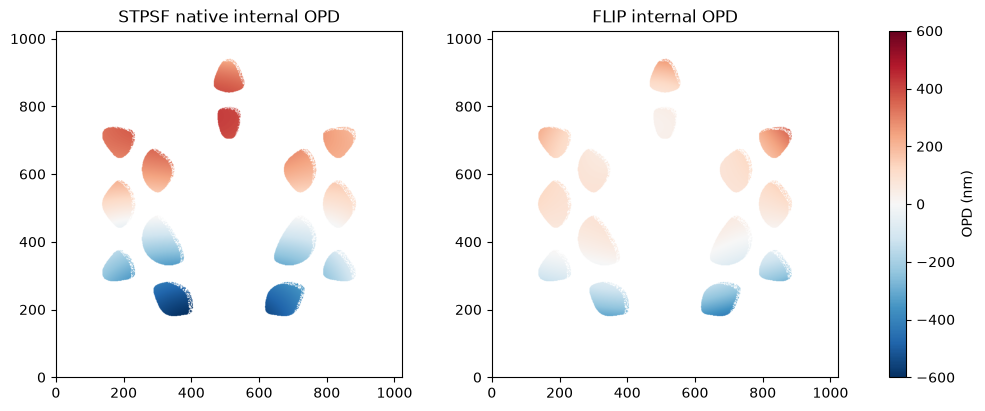

Wavelength (microns): 4.454522695596097
Internal OPD difference RMSE (nm): 190.64315860161187


In [ ]:
# Select the middle wavelength.
wl_index = len(wavelengths) // 2
wl_m = float(wavelengths[wl_index].item())

# Read STPSF's native internal OPD, bypassing our earlier replacement.
native_si_optic = type(inst_matched)._get_aberrations(inst_matched)
stpsf_si_native = native_si_optic.get_opd(wl_m)

# Read the internal OPD actually used by FLIP.
with torch.no_grad():
    flip_si_used = (
        model.nircam_offsets(model.nircam_opd)[0, wl_index]
        .detach().cpu().numpy()
    )

# Compare only the region transmitted by both Lyot stops.
inside = (stpsf_lyot_used > 0) & (flip_lyot_used > 0)

stpsf_map = np.where(inside, stpsf_si_native * 1e9, np.nan)
flip_map = np.where(inside, flip_si_used * 1e9, np.nan)

limit = max(
    np.nanmax(np.abs(stpsf_map)),
    np.nanmax(np.abs(flip_map))
)

fig, axes = plt.subplots(
    1, 2, figsize=(10, 4), constrained_layout=True
)

for ax, image, title in zip(
    axes,
    [stpsf_map, flip_map],
    ["STPSF native internal OPD", "FLIP internal OPD"]
):
    im = ax.imshow(
        image,
        origin="lower",
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit
    )
    ax.set_title(title)

fig.colorbar(im, ax=axes, label="OPD (nm)")
plt.show()

difference_nm = stpsf_map[inside] - flip_map[inside]

print("Wavelength (microns):", wl_m * 1e6)
print("Internal OPD difference RMSE (nm):",
      np.sqrt(np.mean(difference_nm**2)))